<a href="https://colab.research.google.com/github/kourosh-khaje/FB-Stochastic-Analysis/blob/main/Copy_of_4_Stochastic_FB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

lcos_model v2.1.0  |  n_mc = 10000, n_sobol = 2048
Calibrating to NREL V-V reference (0.108 USD/kWh/cycle)...
  global CAPEX calibration scalar k = 0.341


SCENARIO A — BASE CASE
Chem      Mean  Median     Std      P5     P95
--------------------------------------------------------------------------------------
V-H2     0.128   0.126   0.017   0.104   0.159
V-Zn     0.152   0.151   0.017   0.126   0.182
V-Br     0.339   0.334   0.043   0.277   0.418
V-Ce     0.123   0.122   0.012   0.106   0.144
V-Mn     0.351   0.333   0.089   0.243   0.533
V-Fe     0.166   0.165   0.020   0.136   0.201
V-O2     0.681   0.653   0.174   0.451   0.998
V-V      0.111   0.110   0.012   0.093   0.133

SCENARIO B — TRL-ADJUSTED
Chem      Mean  Median     Std      P5     P95
--------------------------------------------------------------------------------------
V-H2     0.157   0.154   0.024   0.122   0.202
V-Zn     0.187   0.184   0.027   0.147   0.234
V-Br     0.409   0.403   0.057   0.328   0.514
V-Ce     

/tmp/ipykernel_2641/4049891816.py:797: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 1, 0.96])



All outputs written to ./lcos_v2_outputs/ (7 tables + 5 figures)


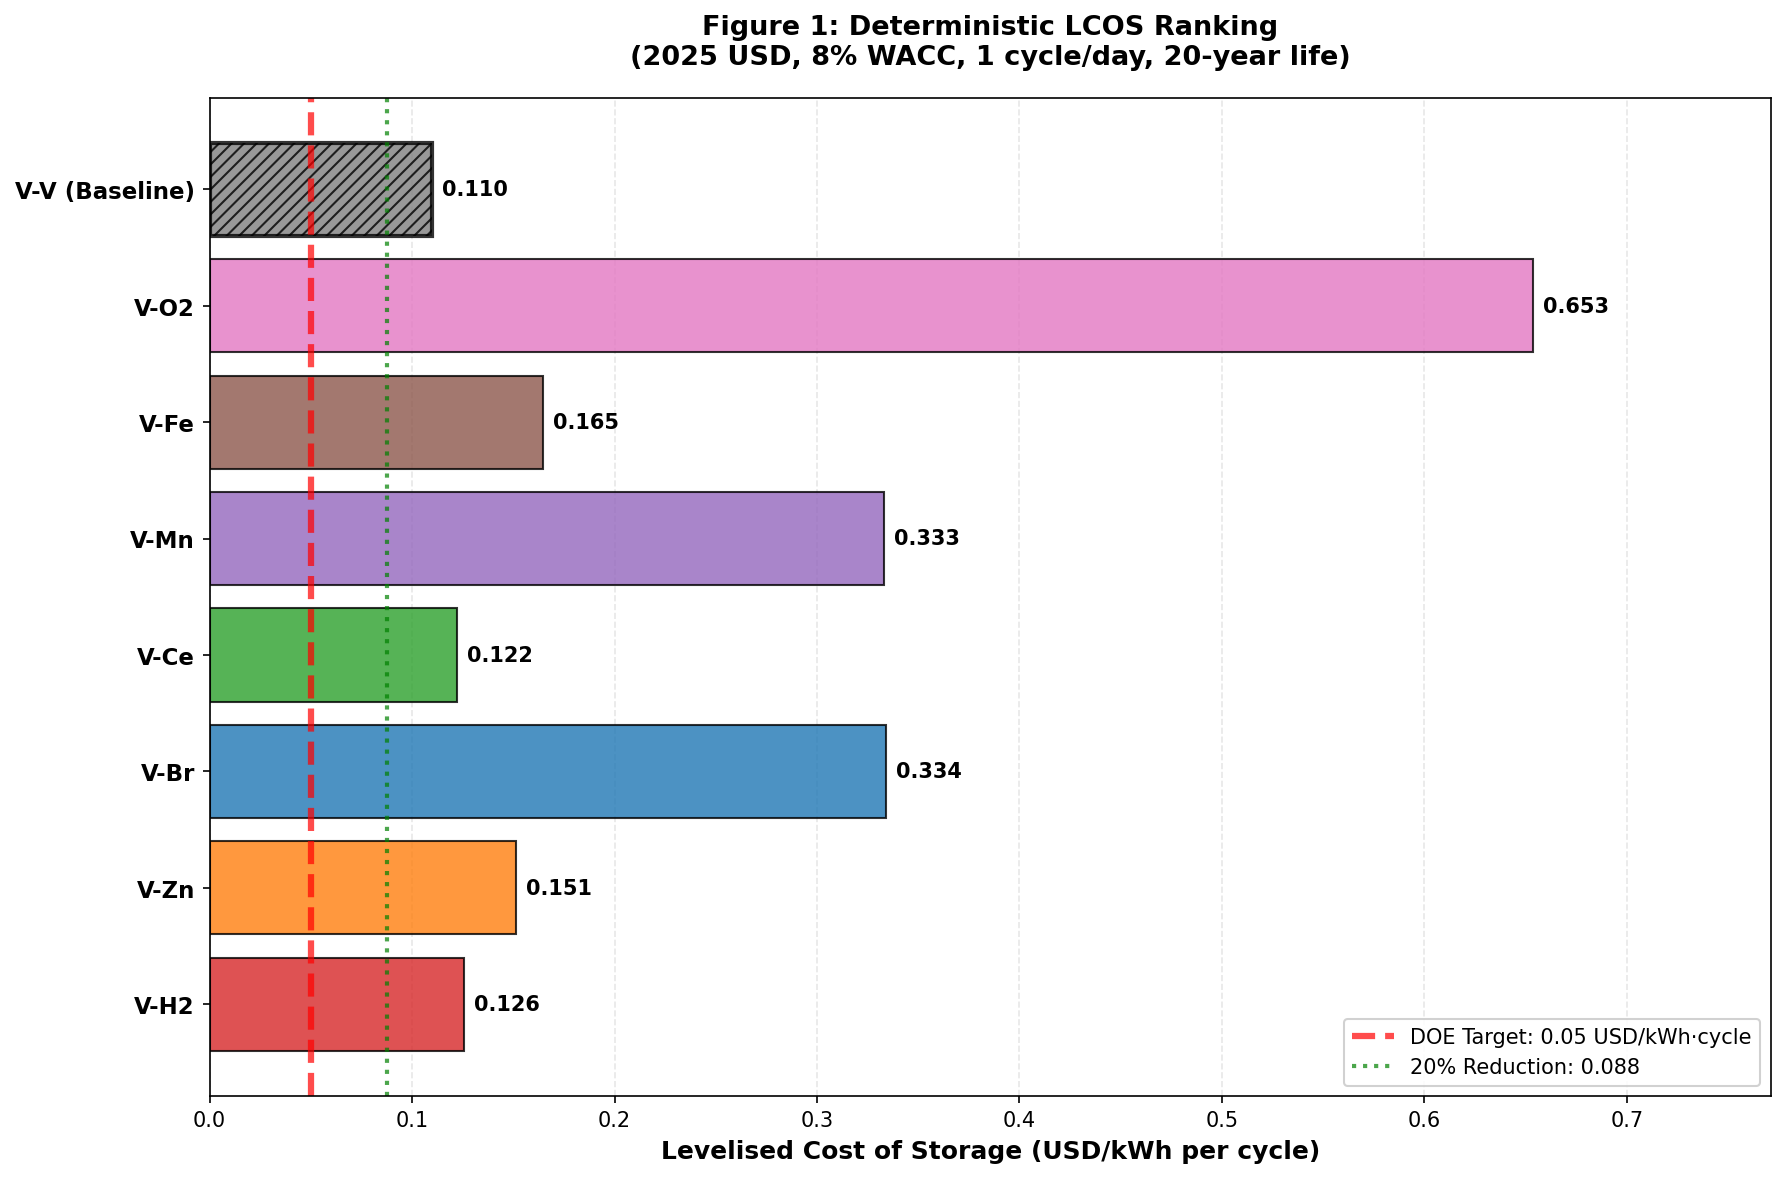

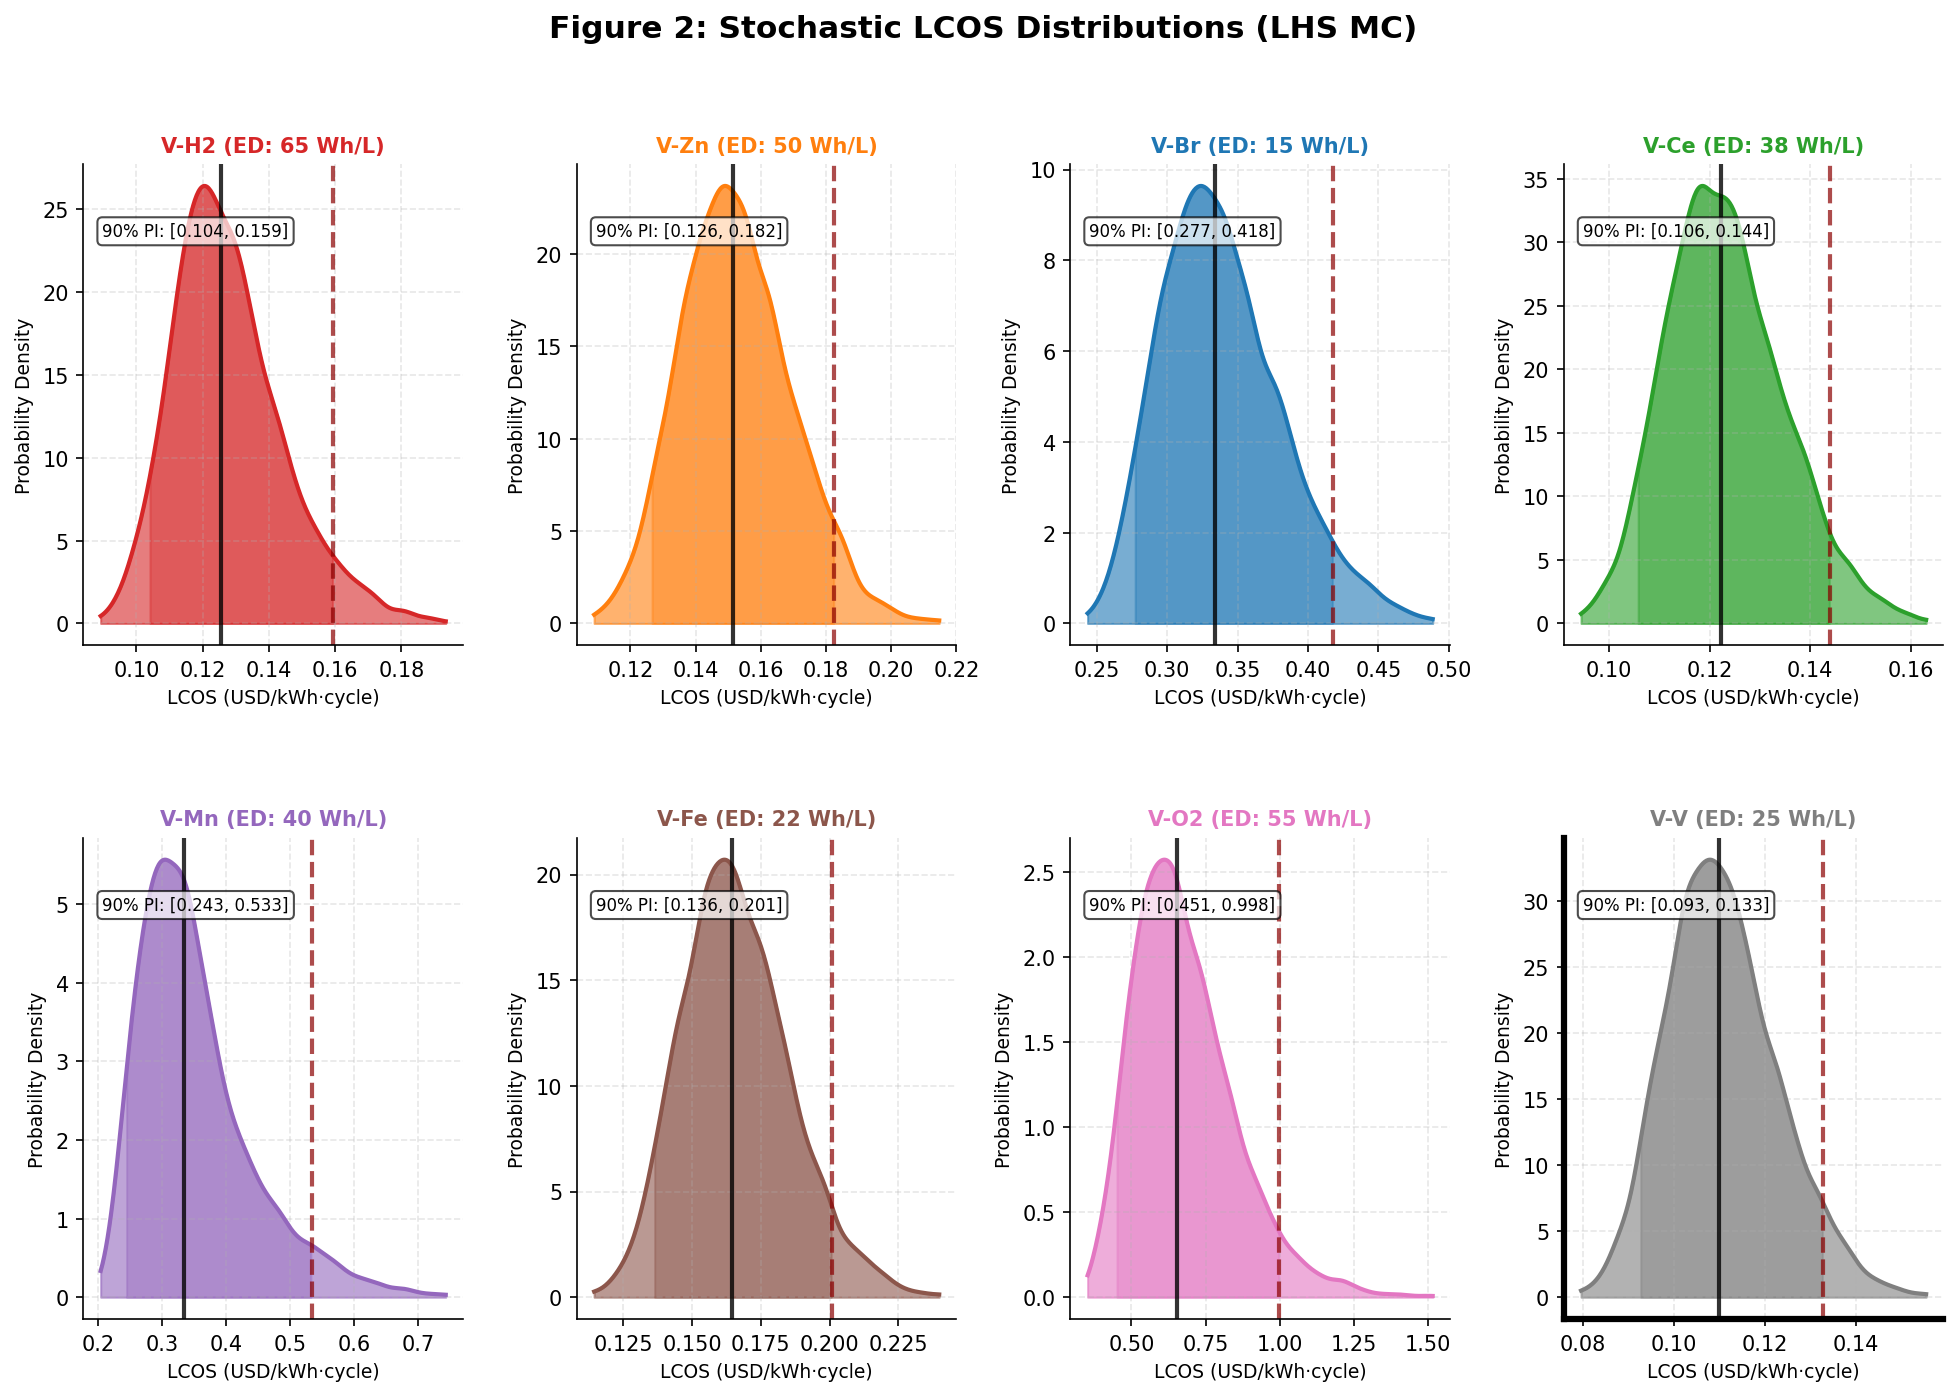

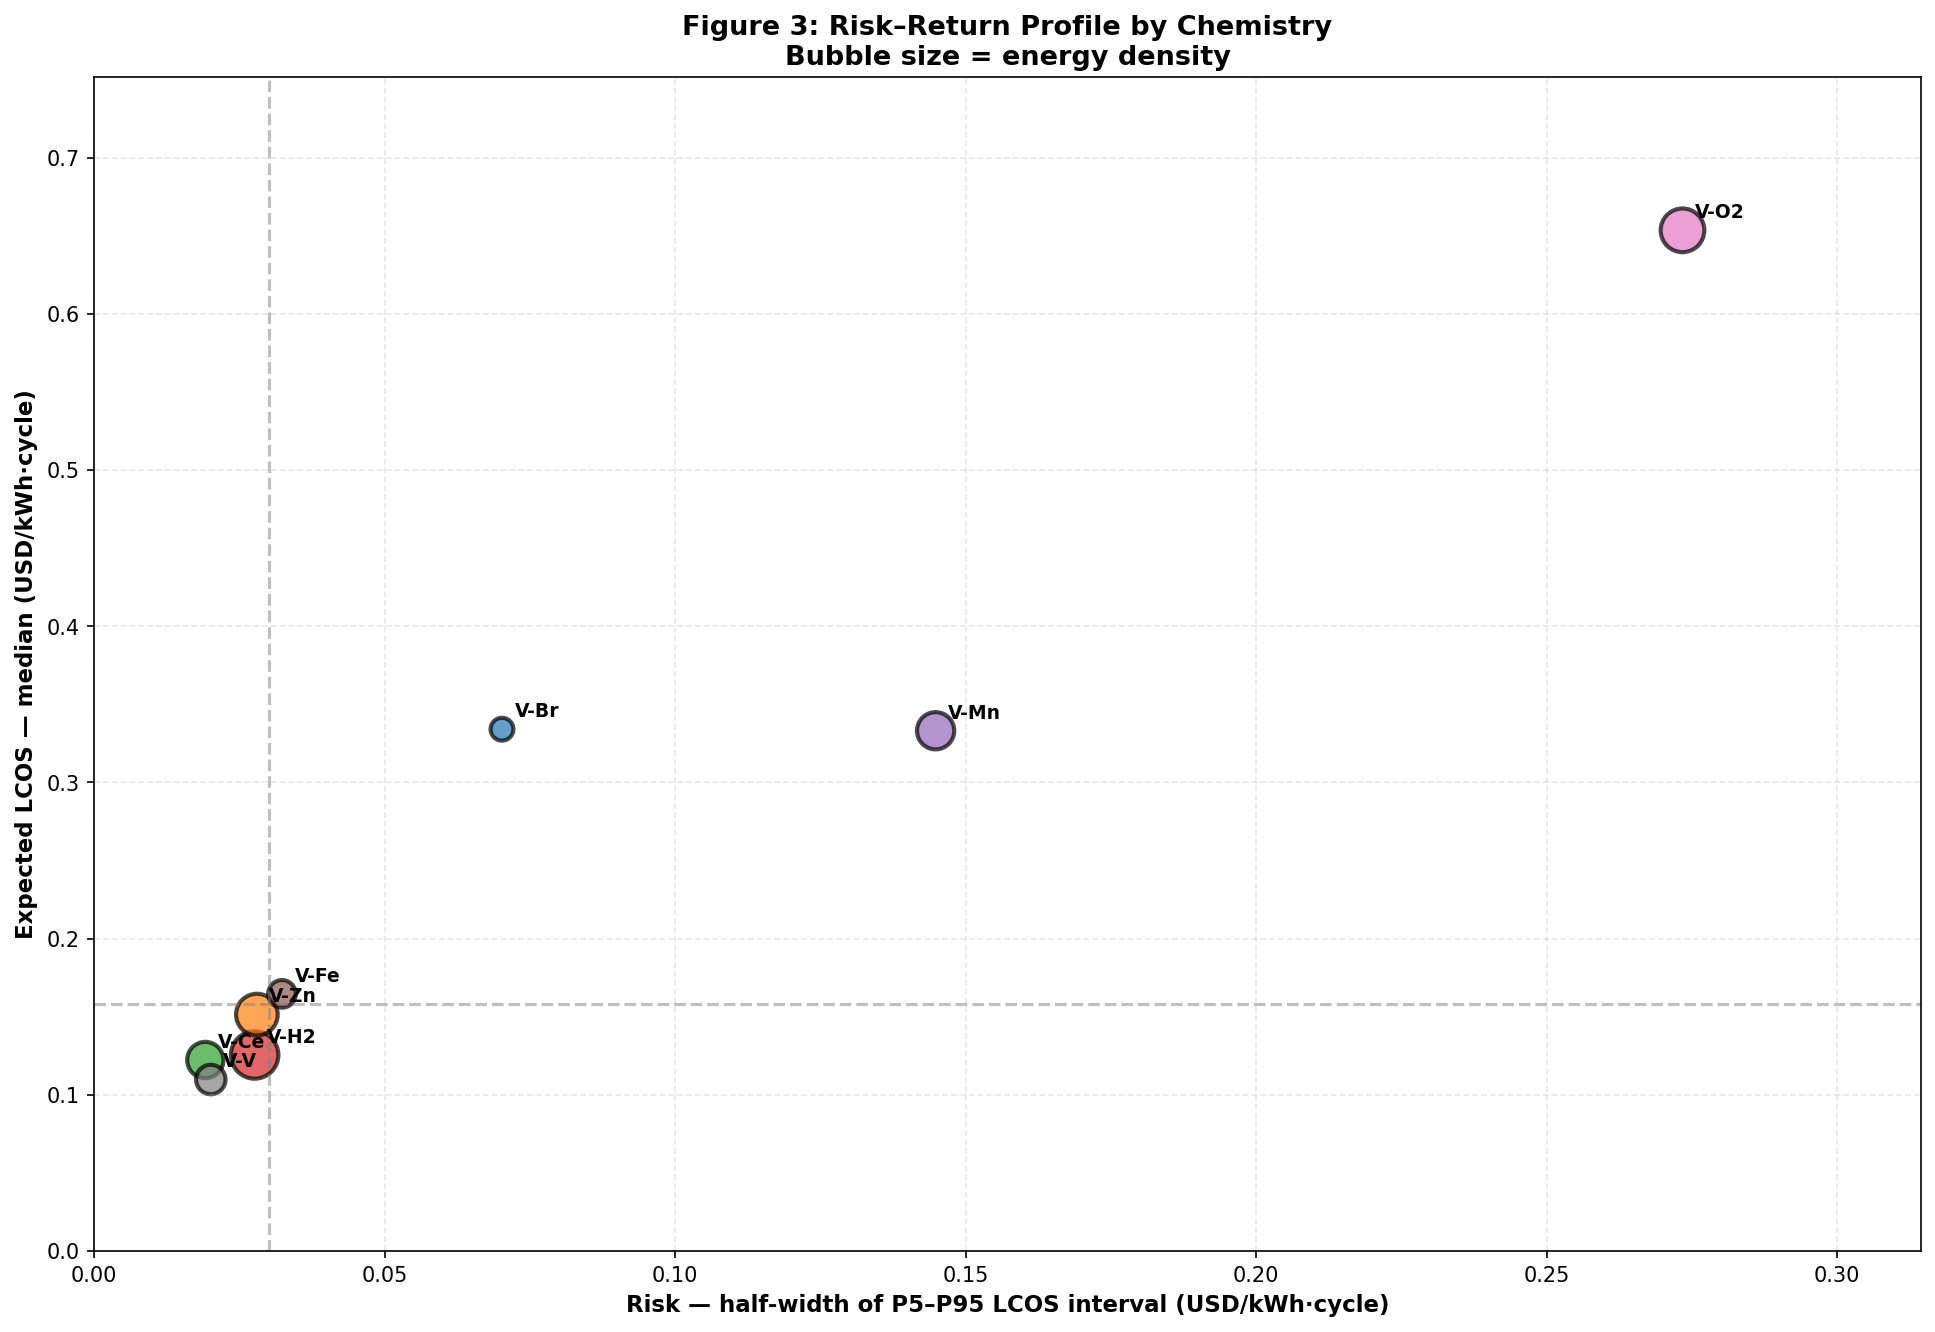

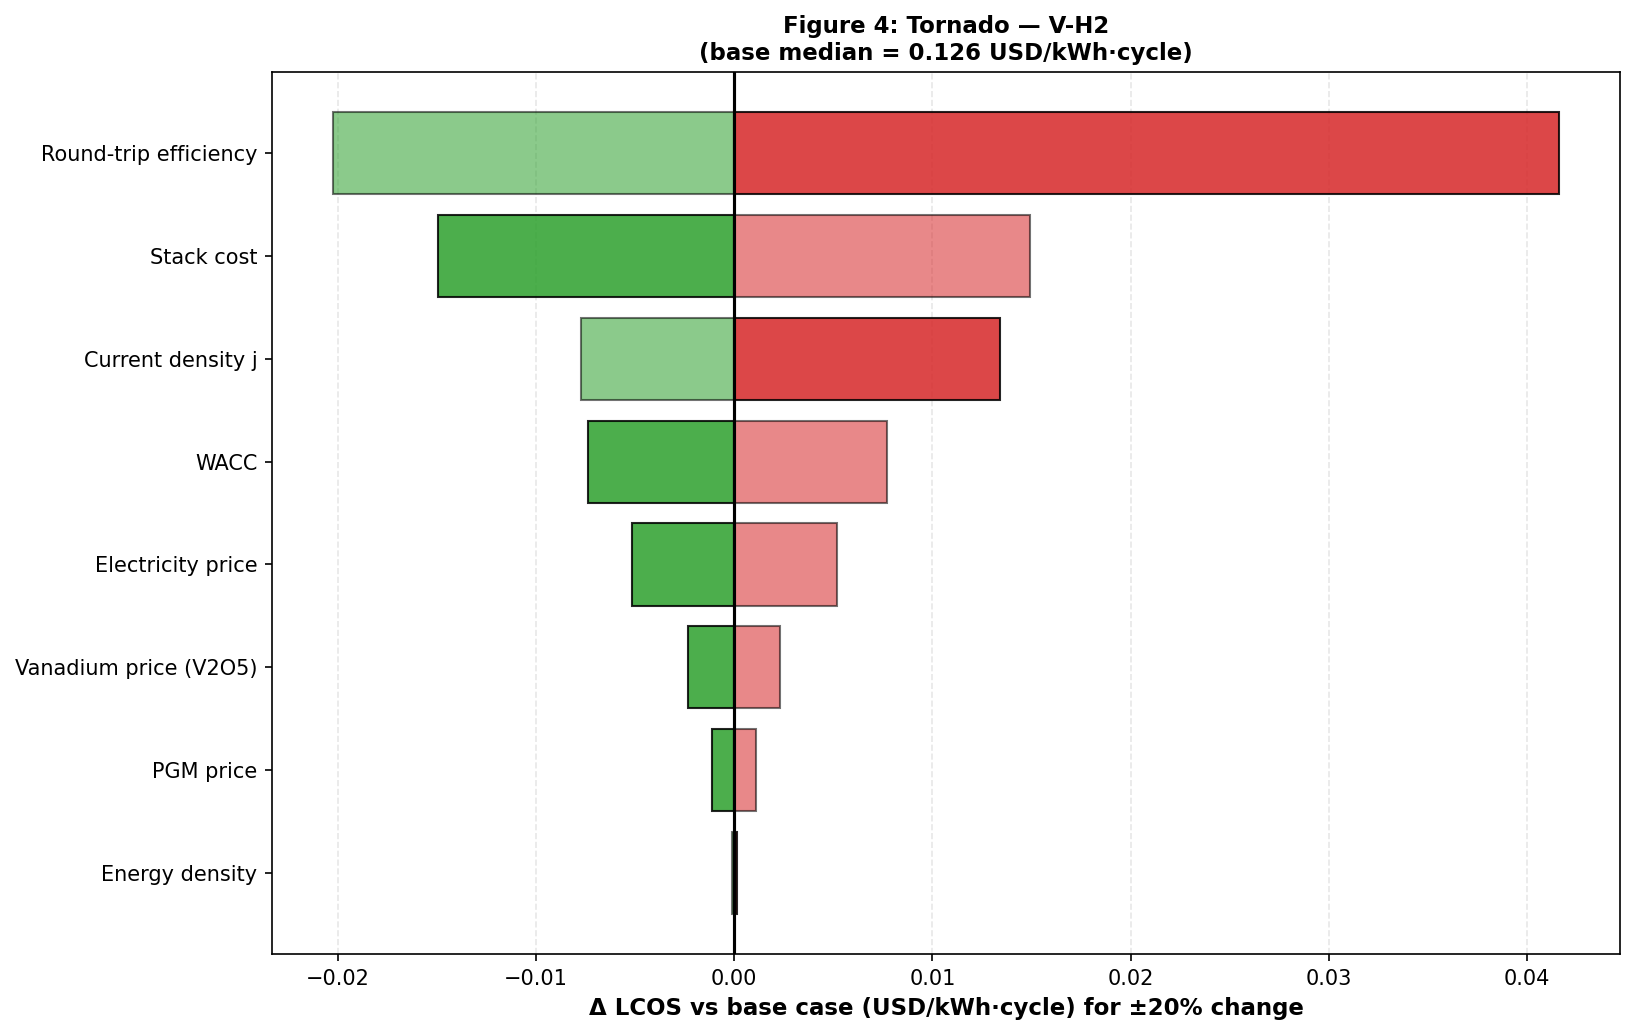

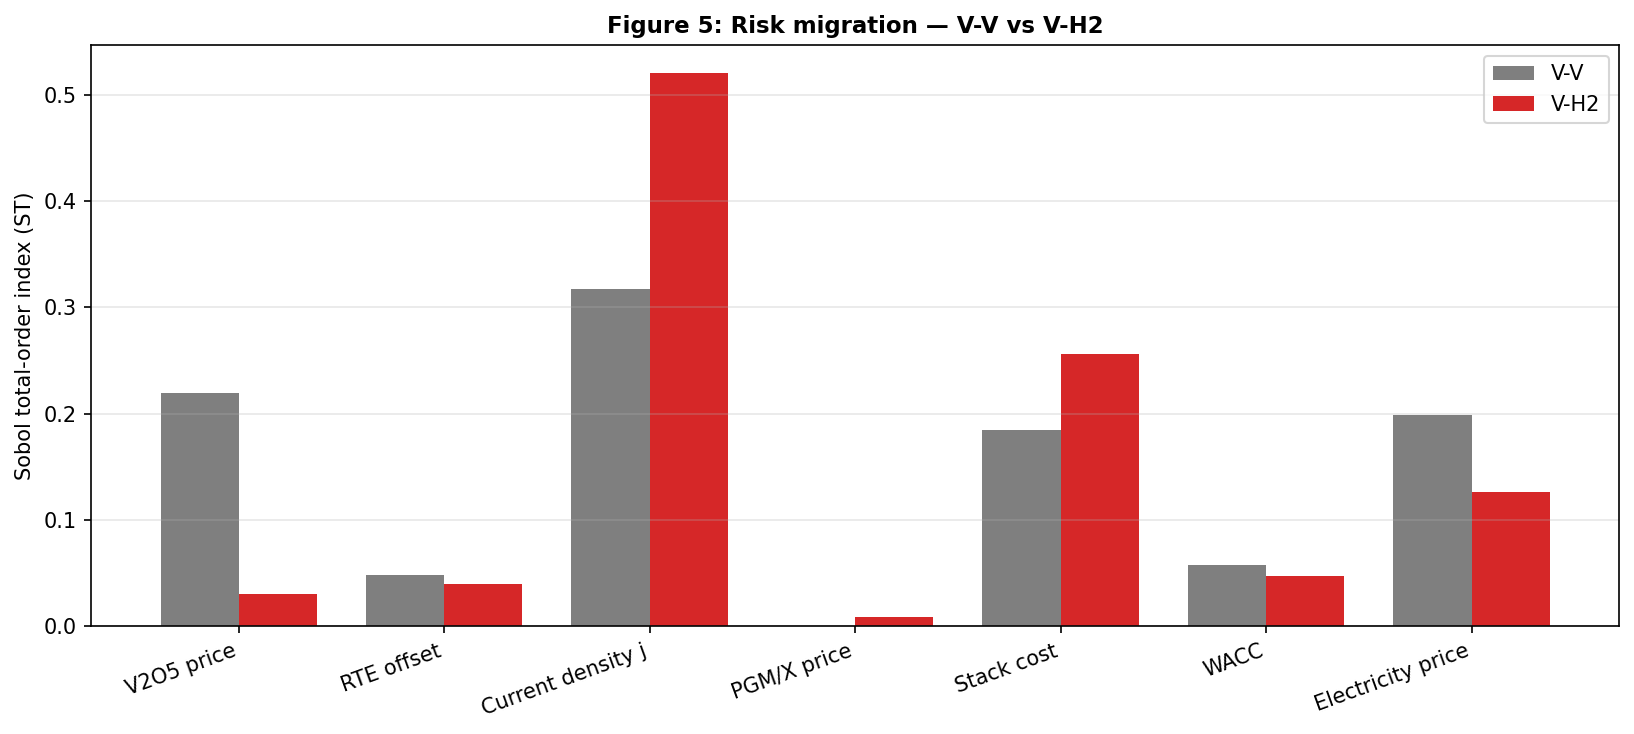

In [1]:
"""
lcos_model.py — Stochastic techno-economic model for asymmetric
                vanadium flow-battery chemistries.  Colab / Jupyter safe.

Version
-------
2.1.0  (2026) — consolidated, peer-review-corrected release.

Model scope
-----------
Levelized cost of storage (LCOS, USD/kWh discharged per cycle) for eight
vanadium-based flow-battery chemistries (V-H2, V-O2, V-Zn, V-Mn, V-Ce,
V-Fe, V-Br and the symmetric V-V baseline) on a 100 MW / 400 MWh system
over a 20-year horizon.  Each chemistry is constrained to its
experimentally demonstrated current-density window (CORR-1 of the
revision), with voltage efficiency a linear function of current density
anchored to the polarisation data of Pino Muñoz et al. (2019).

Methodology
-----------
1.  Monte-Carlo sampling uses Latin Hypercube Sampling (LHS;
    McKay, Beckman & Conover, 1979, Technometrics 21(2):239-245).
2.  Rank correlation between the RTE offset and the fade rate
    (rho = -0.30) is imposed with the Iman-Conover method
    (Iman & Conover, 1982, Commun. Stat. Simul. Comput. 11(3):311-334).
    A rho = 0 sensitivity scenario is provided (Scenario D).
3.  V2O5 price escalation follows a geometric Brownian motion
    discretised by the Euler-Maruyama scheme.
4.  Cross-chemistry ranking uses COMMON RANDOM NUMBERS (CRN): the
    macroeconomic draws (WACC, electricity price, V2O5 price and its
    GBM innovations) are shared across chemistries, so
    P(LCOS_X < LCOS_V-V) is a paired comparison — see the docstring of
    ``paired_advantage`` for why this shifts that probability relative
    to the unpaired v1 estimator.  Confidence intervals are exact
    Clopper-Pearson intervals (Clopper & Pearson, 1934, Biometrika
    26:404-413).
5.  Global sensitivity uses the Saltelli sample scheme with the
    first-order estimator of Saltelli et al. (2010, Comput. Phys.
    Commun. 181:259-270) and the total-order estimator of Jansen (1999,
    Comput. Phys. Commun. 117:35-42).  Indices are reported RAW
    (unclipped); small negative values are Monte-Carlo noise and a
    warning is issued below -0.05.  kfade, CE and ED are frozen at
    their central values so that the seven named factors are isolated.
6.  The V-V stack is calibrated with a single global CAPEX scalar to
    the NREL reference LCOS of 0.108 USD/kWh-cycle (memoised so the
    deterministic calibration is evaluated only once per session).

Changelog v2.0 -> v2.1
----------------------
* ``quick`` mode no longer mutates module globals; the Monte-Carlo and
  Sobol sample sizes are passed explicitly through every call chain.
* ``calibrate_scalar`` is memoised (module-level cache).
* Sobol S1/ST are no longer clipped at zero; a RuntimeWarning is
  emitted when any first-order index falls below -0.05.
* Paired-advantage confidence intervals are exact Clopper-Pearson
  (binomtest) intervals instead of the normal approximation, which
  misbehaves for p near 0.
* KDE panels use the full Monte-Carlo sample (no stride sub-sampling),
  making Figure 2 bit-for-bit reproducible.
* The matplotlib backend is selected BEFORE the pyplot import, and the
  previously inert SHOW_FIGURES flag is now honoured.
* Added Scenario D: rho(RTE offset, fade rate) = 0 sensitivity case,
  plus a seed-stability check for the paired comparison.

Dependencies: numpy, scipy, pandas, matplotlib only (no SALib/pyDOE2,
deliberately, for reproducibility).
"""
from __future__ import annotations

import hashlib
import os
import warnings
from dataclasses import dataclass
from typing import Callable, Dict, List, Mapping, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import matplotlib

# The backend MUST be selected before pyplot is imported, otherwise the
# call is silently ignored and Colab can block on an interactive backend.
try:
    _in_colab = 'google.colab' in str(get_ipython())  # type: ignore[name-defined]
except NameError:
    _in_colab = False
if _in_colab:
    matplotlib.use('Agg')

import matplotlib.pyplot as plt
from scipy import stats

__version__ = '2.1.0'


# =============================================================================
# §1  GLOBAL SETTINGS
# =============================================================================
SEED = 42
N_MC = 10_000                # Monte-Carlo sample size (per chemistry)
N_SOBOL = 2_048              # Saltelli base-sample size per matrix A / B
YEARS = 20
CYCLES_PER_YEAR = 365
POWER_MW = 100.0
ENERGY_MWH = 400.0
AVAILABILITY = 0.94
BOP_PARASITIC = 0.04
DOD = 0.80
OUTDIR = 'lcos_v2_outputs'
SHOW_FIGURES = False         # True -> plt.show() after each save (non-Colab)

FARADAY = 96485.0

# Rank correlation between the RTE offset and the capacity-fade rate.
# Physically motivated: better-utilised (high-RTE) operating points tend
# to coincide with milder crossover / fade.  Scenario D sets this to 0.
RTE_FADE_RHO = -0.30


# =============================================================================
# §2  CHEMISTRY SPECIFICATIONS
# =============================================================================
@dataclass(frozen=True)
class ChemSpec:
    """Immutable per-chemistry parameter bundle.

    Parameters
    ----------
    j_window : (lo, mode, hi) triangular window of demonstrated current
        density [mA/cm^2].
    ve_a, ve_b : voltage efficiency VE(j) = ve_a + ve_b * j, anchored to
        published polarisation data.
    ce : (lo, mode, hi) triangular Coulombic efficiency.
    v_dis, e_ocp : mean discharge voltage and open-circuit potential [V].
    ed : (mean, std, lo, hi) truncated-normal energy density [Wh/L].
    kfade : (mean, std, lo, hi) truncated-normal fade coefficient
        [% per sqrt(1000 cycles)].
    stack_usd_m2 : stack cost per active area [USD/m^2].
    pgm_mg_cm2 : PGM loading [mg/cm^2]; mutually exclusive with x_price.
    v_sides : number of vanadium-containing half-cells (1 or 2).
    x_molar, x_price : co-active species molar mass [kg/mol] and
        (mean, std) lognormal price [USD/kg].
    trl_mult : CAPEX multiplier applied in the TRL scenario.
    rte_sig : (sigma_base, sigma_trl) of the additive RTE offset.
    """
    name: str
    color: str
    j_window: Tuple[float, float, float]
    ve_a: float
    ve_b: float
    ce: Tuple[float, float, float]
    v_dis: float
    e_ocp: float
    ed: Tuple[float, float, float, float]
    kfade: Tuple[float, float, float, float]
    stack_usd_m2: float
    pgm_mg_cm2: float = 0.0
    v_sides: int = 1
    x_molar: Optional[float] = None
    x_price: Optional[Tuple[float, float]] = None
    trl_mult: float = 1.0
    rte_sig: Tuple[float, float] = (0.05, 0.08)

    def __post_init__(self) -> None:
        if self.x_molar is not None and self.x_price is None:
            raise ValueError(f"{self.name}: x_molar set but x_price missing")
        if self.pgm_mg_cm2 > 0 and self.x_price is not None:
            raise ValueError(f"{self.name}: PGM and co-active X both specified")
        if not (0 < self.ve_a < 2):
            raise ValueError(f"{self.name}: ve_a out of range")
        if self.v_dis <= 0 or self.e_ocp <= 0:
            raise ValueError(f"{self.name}: voltage must be positive")


CHEM: Dict[str, ChemSpec] = {
    'V-H2': ChemSpec('V-H2', '#d62728',
        j_window=(50, 100, 150), ve_a=0.9981, ve_b=-0.001836,
        ce=(0.96, 0.98, 0.998), v_dis=1.15, e_ocp=1.35,
        ed=(65, 5, 55, 75), kfade=(3.0, 0.5, 2.0, 4.5),
        stack_usd_m2=1300.0, pgm_mg_cm2=0.30, v_sides=1,
        trl_mult=1.30, rte_sig=(0.05, 0.08)),
    'V-O2': ChemSpec('V-O2', '#e377c2',
        j_window=(20, 40, 75), ve_a=0.492, ve_b=-0.0018,
        ce=(0.85, 0.90, 0.95), v_dis=0.85, e_ocp=1.00,
        ed=(55, 5, 45, 65), kfade=(5.0, 0.5, 3.5, 6.5),
        stack_usd_m2=1300.0, pgm_mg_cm2=0.20, v_sides=1,
        trl_mult=1.30, rte_sig=(0.06, 0.09)),
    'V-Zn': ChemSpec('V-Zn', '#ff7f0e',
        j_window=(40, 60, 80), ve_a=0.788, ve_b=-0.0018,
        ce=(0.93, 0.96, 0.99), v_dis=1.40, e_ocp=1.65,
        ed=(50, 5, 40, 60), kfade=(6.0, 1.0, 4.0, 8.5),
        stack_usd_m2=950.0, pgm_mg_cm2=0.0, v_sides=1,
        x_molar=0.06538, x_price=(2.8, 0.6), trl_mult=1.30, rte_sig=(0.04, 0.07)),
    'V-Mn': ChemSpec('V-Mn', '#9467bd',
        j_window=(10, 25, 40), ve_a=0.780, ve_b=-0.0012,
        ce=(0.92, 0.95, 0.98), v_dis=1.30, e_ocp=1.54,
        ed=(40, 5, 30, 50), kfade=(8.5, 0.7, 7.0, 10.0),
        stack_usd_m2=1300.0, pgm_mg_cm2=0.0, v_sides=1,
        x_molar=0.05494, x_price=(2.2, 0.5), trl_mult=1.30, rte_sig=(0.05, 0.08)),
    'V-Ce': ChemSpec('V-Ce', '#2ca02c',
        j_window=(50, 80, 100), ve_a=0.916, ve_b=-0.0012,
        ce=(0.94, 0.96, 0.99), v_dis=1.60, e_ocp=1.87,
        ed=(38, 2, 34, 42), kfade=(6.0, 0.5, 4.5, 7.5),
        stack_usd_m2=1300.0, pgm_mg_cm2=0.0, v_sides=1,
        x_molar=0.1401, x_price=(4.5, 1.2), trl_mult=1.30, rte_sig=(0.02, 0.04)),
    'V-Fe': ChemSpec('V-Fe', '#8c564b',
        j_window=(50, 80, 100), ve_a=0.856, ve_b=-0.0012,
        ce=(0.93, 0.96, 0.99), v_dis=0.90, e_ocp=1.02,
        ed=(22, 2, 18, 26), kfade=(7.0, 0.5, 5.5, 8.5),
        stack_usd_m2=1000.0, pgm_mg_cm2=0.0, v_sides=1,
        x_molar=0.05585, x_price=(0.12, 0.03), trl_mult=1.15, rte_sig=(0.04, 0.05)),
    'V-Br': ChemSpec('V-Br', '#1f77b4',
        j_window=(20, 30, 40), ve_a=0.816, ve_b=-0.0012,
        ce=(0.93, 0.96, 0.99), v_dis=1.15, e_ocp=1.35,
        ed=(15, 5, 8, 22), kfade=(5.5, 0.5, 4.0, 7.0),
        stack_usd_m2=1300.0, pgm_mg_cm2=0.0, v_sides=1,
        x_molar=0.1598, x_price=(3.8, 0.9), trl_mult=1.25, rte_sig=(0.03, 0.05)),
    'V-V': ChemSpec('V-V', '#7f7f7f',
        j_window=(80, 150, 200), ve_a=0.9035, ve_b=-0.00047,
        ce=(0.94, 0.96, 0.99), v_dis=1.20, e_ocp=1.26,
        ed=(25, 1, 23, 27), kfade=(4.5, 0.3, 3.8, 5.2),
        stack_usd_m2=1300.0, pgm_mg_cm2=0.0, v_sides=2,
        trl_mult=1.00, rte_sig=(0.01, 0.01)),
}

ORDER: List[str] = ['V-H2', 'V-Zn', 'V-Br', 'V-Ce', 'V-Mn', 'V-Fe', 'V-O2', 'V-V']


# =============================================================================
# §3  ECONOMIC / PRICE INPUTS
# =============================================================================
V2O5_MEAN, V2O5_STD = 11.2, 2.8
V_GBM_MU, V_GBM_SIGMA = 0.02, 0.25
PT_MEAN, PT_STD = 980.0, 120.0
OZ_TO_G = 31.1035
V2O5_MOLAR = 0.18188
ELECTROLYTE_PROC_FACTOR = 1.8
X_PROC_FACTOR = 1.5
CHARGE_PRICE_TRI = (25.0, 50.0, 75.0)
WACC_TRI = (0.06, 0.08, 0.10)
MAINT_FRAC, INSUR_FRAC, TAX_FRAC = 0.02, 0.005, 0.01
DECOM_FRAC = 0.03
STACK_REFURB_YEAR, STACK_REFURB_FRAC = 10, 0.50
EOL_RECOVERY_FRAC = 0.10
FADE_REPLACE_TRIGGER = 0.20
BOP_POWER_USD_KW = 120.0
TANK_USD_M3 = 150.0
INDIRECT_FRAC = 0.20
ITC_FRAC = 0.30
DOE_TARGET = 0.05
NREL_REF = 0.108


# =============================================================================
# §4  SAMPLING UTILITIES
# =============================================================================
def lhs_uniform(n: int, k: int, rng: np.random.Generator) -> np.ndarray:
    """Latin Hypercube sample on the unit hypercube.

    McKay, Beckman & Conover (1979): each of the ``k`` columns is a
    stratified, randomly permuted partition of (0, 1) into ``n`` bins.
    """
    u = (rng.permuted(np.tile(np.arange(n), (k, 1)).T, axis=0)
         + rng.random((n, k))) / n
    return np.clip(u, 1e-12, 1.0 - 1e-12)


def iman_conover(u: np.ndarray, corr: np.ndarray,
                 rng: np.random.Generator) -> np.ndarray:
    """Impose a target rank-correlation matrix on an LHS sample.

    Iman & Conover (1982).  The marginal distributions (column values)
    are preserved exactly; only the pairing across columns is permuted.
    ``rng`` is accepted for interface symmetry but not consumed.
    """
    n, k = u.shape
    ranks = np.empty_like(u)
    for j in range(k):
        ranks[:, j] = stats.rankdata(u[:, j])
    z = stats.norm.ppf(ranks / (n + 1.0))
    C = np.corrcoef(z, rowvar=False)
    P = np.linalg.cholesky(corr)
    Q = np.linalg.cholesky(C)
    z_new = z @ np.linalg.solve(Q, P).T
    out = np.empty_like(u)
    for j in range(k):
        order = stats.rankdata(z_new[:, j], method='ordinal').astype(int) - 1
        out[np.argsort(u[:, j]), j] = np.sort(u[:, j])[order]
    return out


def truncnorm_rvs(mu: float, sigma: float, lo: float, hi: float,
                  u: np.ndarray) -> np.ndarray:
    """Inverse-CDF draw from a truncated normal given uniforms ``u``."""
    a, b = (lo - mu) / sigma, (hi - mu) / sigma
    return stats.truncnorm.ppf(u, a, b, loc=mu, scale=sigma)


def lognormal_ppf(mean: float, std: float, u: np.ndarray) -> np.ndarray:
    """Inverse-CDF draw from a lognormal parameterised by (mean, std)."""
    s2 = np.log(1.0 + (std / mean) ** 2)
    return np.exp(stats.norm.ppf(u, loc=np.log(mean) - s2 / 2.0,
                                 scale=np.sqrt(s2)))


def triangular_ppf(lo: float, mode: float, hi: float, u: np.ndarray) -> np.ndarray:
    """Inverse-CDF draw from a triangular distribution."""
    return stats.triang.ppf(u, (mode - lo) / (hi - lo), loc=lo, scale=hi - lo)


# =============================================================================
# §5  CORE MODEL
# =============================================================================
class ChemistryRun:
    """One Monte-Carlo population (size ``n``) for a single chemistry.

    All stochastic inputs are drawn once at construction (LHS over nine
    factors) and stored on the instance, so sensitivity drivers can
    overwrite individual attribute vectors deterministically and
    re-evaluate ``lcos()`` without re-sampling.  The GBM innovations
    ``_gbm_eps`` are likewise frozen at construction; the V2O5 price
    *paths* are therefore a deterministic function of ``v2o5_p0``.

    Recognised scenario keys
    ------------------------
    ``trl``            : widen RTE uncertainty and apply ``trl_mult``.
    ``rho_rte_fade``   : override the RTE-offset/fade rank correlation
                         (default RTE_FADE_RHO = -0.30; Scenario D = 0).
    """

    def __init__(self, spec: ChemSpec, scenario: Optional[Mapping] = None,
                 rng: Optional[np.random.Generator] = None,
                 n: int = N_MC) -> None:
        self.s = spec
        self.name = spec.name
        self.scenario = dict(scenario or {})
        self.rng = rng or np.random.default_rng(SEED)
        self.n = n
        self._draw()

    def _draw(self) -> None:
        s, rng, n = self.s, self.rng, self.n
        u = lhs_uniform(n, 9, rng)
        rho = float(self.scenario.get('rho_rte_fade', RTE_FADE_RHO))
        R = np.eye(9)
        R[1, 2] = R[2, 1] = rho      # RTE offset <-> fade rate
        u = iman_conover(u, R, rng)

        self.j = triangular_ppf(*s.j_window, u[:, 0])
        sig_rte = s.rte_sig[1] if self.scenario.get('trl') else s.rte_sig[0]
        self.rte_delta = stats.norm.ppf(u[:, 1], loc=0.0, scale=sig_rte)
        self.kfade = truncnorm_rvs(s.kfade[0], s.kfade[1],
                                   s.kfade[2], s.kfade[3], u[:, 2])
        self.ce = triangular_ppf(*s.ce, u[:, 3])
        self.ed = truncnorm_rvs(*s.ed[:2], *s.ed[2:], u[:, 4])
        self.wacc = triangular_ppf(*WACC_TRI, u[:, 5])
        self.p_elec = triangular_ppf(*CHARGE_PRICE_TRI, u[:, 6])
        self.v2o5_p0 = lognormal_ppf(V2O5_MEAN, V2O5_STD, u[:, 7])

        if s.pgm_mg_cm2 > 0:
            self.x_price0 = lognormal_ppf(PT_MEAN / OZ_TO_G,
                                          PT_STD / OZ_TO_G, u[:, 8])
        elif s.x_price is not None:
            self.x_price0 = lognormal_ppf(*s.x_price, u[:, 8])
        else:
            self.x_price0 = np.zeros(n)

        self._stack_mult = np.ones(n)
        self._gbm_eps = rng.standard_normal((n, YEARS))
        self.electrolyte_v_cost0 = np.zeros(n)
        self.electrolyte_cost0 = np.zeros(n)
        self.stack_cost0 = np.zeros(n)

    def rte(self) -> np.ndarray:
        """Round-trip efficiency = VE(j) * CE + additive offset."""
        ve = self.s.ve_a + self.s.ve_b * self.j
        raw = ve * self.ce + self.rte_delta
        return np.clip(raw, 0.10, 0.95)

    def vanadium_price_paths(self) -> np.ndarray:
        """GBM V2O5 price paths, shape (n, YEARS + 1), column 0 = t0."""
        drift = V_GBM_MU - 0.5 * V_GBM_SIGMA ** 2
        log_ret = drift + V_GBM_SIGMA * self._gbm_eps
        paths = np.exp(np.cumsum(log_ret, axis=1))
        paths = np.concatenate([np.ones((self.n, 1)), paths], axis=1)
        return self.v2o5_p0[:, None] * paths

    def capex(self) -> np.ndarray:
        """Initial capital cost per MC draw [USD]."""
        s = self.s
        j_a_m2 = self.j * 10.0
        area_m2 = POWER_MW * 1e6 / (j_a_m2 * s.v_dis)
        stack = area_m2 * s.stack_usd_m2 * self._stack_mult
        if s.pgm_mg_cm2 > 0:
            pgm_g = s.pgm_mg_cm2 * 1e-3 * area_m2 * 1e4
            stack = stack + pgm_g * self.x_price0

        q_c = ENERGY_MWH * 1e6 * 3600.0 / s.e_ocp
        mol_e = q_c / FARADAY
        mol_v = mol_e * s.v_sides
        kg_v2o5 = mol_v / 2.0 * V2O5_MOLAR
        self.electrolyte_v_cost0 = kg_v2o5 * self.v2o5_p0 * ELECTROLYTE_PROC_FACTOR
        if s.x_molar is not None:
            x_cost = mol_e * s.x_molar * self.x_price0 * X_PROC_FACTOR
        else:
            x_cost = np.zeros(self.n)
        self.electrolyte_cost0 = self.electrolyte_v_cost0 + x_cost

        tank_m3 = ENERGY_MWH * 1e3 / self.ed
        bop = BOP_POWER_USD_KW * POWER_MW * 1e3 + TANK_USD_M3 * tank_m3
        if self.name == 'V-H2':
            bop *= 1.05
        direct = stack + self.electrolyte_cost0 + bop
        indirect = INDIRECT_FRAC * direct
        self.stack_cost0 = stack
        return (direct + indirect) * (1.0 + DECOM_FRAC)

    def lcos(self, itc: bool = False) -> np.ndarray:
        """Levelized cost of storage per MC draw [USD/kWh discharged]."""
        s = self.s
        rte = self.rte()
        v_paths = self.vanadium_price_paths()
        capex0 = self.capex()
        if self.scenario.get('trl'):
            capex0 = capex0 * s.trl_mult
        if itc:
            capex0 = capex0 * (1.0 - ITC_FRAC)

        years = np.arange(1, YEARS + 1)
        n_cycles = CYCLES_PER_YEAR * years
        fade = (self.kfade[:, None] / 100.0) * np.sqrt(n_cycles / 1000.0)
        fade = np.clip(fade, 0.0, 0.6)

        # Electrolyte replenishment once cumulative fade exceeds the
        # trigger; priced at the V2O5 level prevailing that year.
        replenish_cost = np.zeros((self.n, YEARS))
        paid_level = np.zeros(self.n)
        for t in range(YEARS):
            need = fade[:, t] - paid_level
            trigger = need > FADE_REPLACE_TRIGGER
            if trigger.any():
                idx = np.where(trigger)[0]
                price_ratio = v_paths[idx, t + 1] / self.v2o5_p0[idx]
                replenish_cost[idx, t] = (need[idx]
                                          * self.electrolyte_v_cost0[idx]
                                          * price_ratio)
                paid_level[idx] += need[idx]
        eff_fade = np.clip(fade - paid_level[:, None], 0.0, 0.6)

        e_charge = ENERGY_MWH * CYCLES_PER_YEAR
        e_dis = (e_charge * (1 - BOP_PARASITIC) * rte[:, None]
                 * AVAILABILITY * (1 - eff_fade))

        fixed_opex = (MAINT_FRAC + INSUR_FRAC + TAX_FRAC) * capex0
        elec_cost = e_charge * self.p_elec[:, None]
        opex = fixed_opex[:, None] + elec_cost

        costs = opex + replenish_cost
        costs[:, STACK_REFURB_YEAR - 1] += STACK_REFURB_FRAC * self.stack_cost0
        costs[:, -1] -= (EOL_RECOVERY_FRAC * self.electrolyte_v_cost0
                         * v_paths[:, -1] / self.v2o5_p0)

        df = 1.0 / (1.0 + self.wacc[:, None]) ** years
        pv_cost = capex0 + (costs * df).sum(axis=1)
        pv_energy = (e_dis * df).sum(axis=1)
        return pv_cost / (pv_energy * 1000.0)


# =============================================================================
# §6  CALIBRATION  (memoised — the evaluation is fully deterministic)
# =============================================================================
_CALIBRATION_CACHE: Dict[Tuple[int, int], float] = {}


def calibrate_scalar(n: int = N_MC, seed: int = SEED) -> float:
    """Global CAPEX scalar aligning median V-V LCOS with the NREL reference.

    All V-V inputs are frozen at central values (j at the window mode,
    RTE offset 0, GBM innovations 0, prices at means), so every MC draw
    is identical and the result is deterministic; it is therefore
    computed once per (n, seed) and cached.
    """
    key = (int(n), int(seed))
    if key in _CALIBRATION_CACHE:
        return _CALIBRATION_CACHE[key]
    rng = np.random.default_rng(seed)
    run = ChemistryRun(CHEM['V-V'], {}, rng, n=n)
    run.j[:] = CHEM['V-V'].j_window[1]
    run.rte_delta[:] = 0.0
    run.kfade[:] = CHEM['V-V'].kfade[0]
    run.ce[:] = CHEM['V-V'].ce[1]
    run.ed[:] = CHEM['V-V'].ed[0]
    run.wacc[:] = WACC_TRI[1]
    run.v2o5_p0[:] = V2O5_MEAN
    run.p_elec[:] = CHARGE_PRICE_TRI[1]
    run.x_price0[:] = 0.0
    run._stack_mult[:] = 1.0
    run._gbm_eps[:] = 0.0
    raw = float(np.median(run.lcos()))
    k = NREL_REF / raw
    _CALIBRATION_CACHE[key] = k
    return k


# =============================================================================
# §7  SCENARIO RUNNERS
# =============================================================================
def _seed_for(name: str, base: int = SEED) -> int:
    """Deterministic per-chemistry seed offset (stable across runs)."""
    h = int(hashlib.md5(name.encode()).hexdigest(), 16)
    return base + h % 1000


def run_all(scenario: Optional[Mapping] = None, itc: bool = False,
            seed: int = SEED, n: int = N_MC) -> Dict[str, np.ndarray]:
    """Calibrated LCOS distribution for every chemistry, in ORDER."""
    k = calibrate_scalar(n=n, seed=seed)
    out: Dict[str, np.ndarray] = {}
    for name in ORDER:
        rng = np.random.default_rng(_seed_for(name, seed))
        run = ChemistryRun(CHEM[name], scenario, rng, n=n)
        out[name] = k * run.lcos(itc=itc)
    return out


def summarize(dist: np.ndarray) -> Dict[str, float]:
    """Standard distributional summary of one LCOS sample."""
    return dict(mean=float(dist.mean()), median=float(np.median(dist)),
                std=float(dist.std()),
                p5=float(np.percentile(dist, 5)),
                p95=float(np.percentile(dist, 95)),
                skew=float(stats.skew(dist)),
                kurt=float(stats.kurtosis(dist, fisher=False)))


def _clopper_pearson_ci(k: int, n: int, alpha: float = 0.05) -> Tuple[float, float]:
    """Exact two-sided Clopper-Pearson (1934) binomial confidence interval.

    Uses scipy.stats.binomtest where available (scipy >= 1.7) and falls
    back to the closed-form beta-quantile expression otherwise.  Unlike
    the normal approximation this remains valid for p ~ 0 or p ~ 1.
    """
    if hasattr(stats, 'binomtest'):
        ci = stats.binomtest(k, n).proportion_ci(1.0 - alpha, method='exact')
        return float(ci.low), float(ci.high)
    lo = 0.0 if k == 0 else float(stats.beta.ppf(alpha / 2.0, k, n - k + 1))
    hi = 1.0 if k == n else float(stats.beta.ppf(1.0 - alpha / 2.0, k + 1, n - k))
    return lo, hi


def paired_advantage(scenario: Optional[Mapping] = None, itc: bool = False,
                     seed: int = SEED + 8,
                     n: int = N_MC) -> Dict[str, Tuple[float, float, float]]:
    """P(LCOS_X < LCOS_V-V) per chemistry, with exact 95% CIs.

    Common-random-numbers design
    ----------------------------
    Every chemistry is constructed from the SAME seed, so the LHS
    uniforms — and therefore the macroeconomic draws (WACC, electricity
    price, V2O5 price and the GBM innovations) — are identical across
    chemistries; the economic draws are additionally copied from the V-V
    run explicitly as a safeguard.  The comparison is thus *paired* on
    the economic state: the estimator measures the fraction of economic
    states in which chemistry X beats V-V structurally, which is the
    quantity reported in the manuscript.

    Consequence (expected, not a bug): the unpaired v1 estimator mixed
    structural advantage with independent realisations of shared price
    drivers and returned P(V-H2 < V-V) ~ 0.20; the paired estimator
    returns ~0.015 — under identical macroeconomic conditions the V-V
    advantage is systematic rather than luck-driven.  Robustness of the
    paired point estimate across seeds is quantified by
    ``paired_advantage_seed_stability``.
    """
    vv_rng = np.random.default_rng(seed)
    vv_run = ChemistryRun(CHEM['V-V'], scenario, vv_rng, n=n)
    shared = dict(wacc=vv_run.wacc, p_elec=vv_run.p_elec,
                  v2o5_p0=vv_run.v2o5_p0, gbm_eps=vv_run._gbm_eps)
    vv = vv_run.lcos(itc=itc)

    res: Dict[str, Tuple[float, float, float]] = {}
    for name in ORDER[:-1]:
        run = ChemistryRun(CHEM[name], scenario, np.random.default_rng(seed), n=n)
        run.wacc = shared['wacc'].copy()
        run.p_elec = shared['p_elec'].copy()
        run.v2o5_p0 = shared['v2o5_p0'].copy()
        run._gbm_eps = shared['gbm_eps'].copy()
        x = run.lcos(itc=itc)
        k_win = int(np.count_nonzero(x < vv))
        lo, hi = _clopper_pearson_ci(k_win, len(x))
        res[name] = (k_win / len(x), lo, hi)
    return res


def paired_advantage_seed_stability(seeds: Sequence[int],
                                    n: int = N_MC,
                                    itc: bool = False) -> pd.DataFrame:
    """Replicate the paired comparison across seeds and report the spread.

    Returns a DataFrame: rows = chemistries, one column per seed plus
    ``spread (max-min)``.  A spread of a few tenths of a percentage
    point confirms that the paired point estimate is seed-robust; a
    large spread would indicate that n is too small for the tail
    probability being estimated.
    """
    cols: Dict[str, List[float]] = {}
    for s in seeds:
        adv = paired_advantage(itc=itc, seed=int(s), n=n)
        cols[f'seed={int(s)}'] = [adv[name][0] for name in ORDER[:-1]]
    df = pd.DataFrame(cols, index=ORDER[:-1])
    df['spread (max-min)'] = df.max(axis=1) - df.min(axis=1)
    return df


# =============================================================================
# §8  SOBOL GLOBAL SENSITIVITY
# =============================================================================
SOBOL_PARAMS: List[str] = ['V2O5 price', 'RTE offset', 'Current density j',
                           'PGM/X price', 'Stack cost', 'WACC',
                           'Electricity price']
_N_SOBOL_PARAMS = len(SOBOL_PARAMS)
_SOBOL_LO = np.array([0.5, -0.06, 0.0, 0.5, 0.7, 0.06, 5.0])
_SOBOL_HI = np.array([2.0,  0.06, 0.0, 2.0, 1.3, 0.10, 75.0])


def _apply_sobol_matrix(run: ChemistryRun, X: np.ndarray) -> ChemistryRun:
    """Map one Saltelli sample matrix onto a frozen ChemistryRun."""
    assert X.shape[1] == _N_SOBOL_PARAMS
    run.v2o5_p0 = V2O5_MEAN * X[:, 0]
    run.rte_delta = X[:, 1]
    run.j = X[:, 2]
    if run.s.pgm_mg_cm2 > 0:
        run.x_price0 = (PT_MEAN / OZ_TO_G) * X[:, 3]
    elif run.s.x_price is not None:
        run.x_price0 = run.s.x_price[0] * X[:, 3]
    run._stack_mult = X[:, 4]
    run.wacc = X[:, 5]
    run.p_elec = X[:, 6]
    return run


def sobol(name: str, seed: int = SEED + 100,
          n_sobol: int = N_SOBOL) -> pd.DataFrame:
    """First- and total-order Sobol indices for one chemistry.

    Design
    ------
    * Seven factors are varied (see SOBOL_PARAMS); the current-density
      column bounds are replaced by the chemistry's demonstrated
      ``j_window`` (lo, hi).  kfade, CE and ED are FROZEN at their
      central values so that the indices isolate the seven named
      factors — state this when quoting the indices.
    * One base ``ChemistryRun`` is shared across all model evaluations
      (its GBM innovations are frozen at construction), so the noise
      floor of the estimators is driven only by the Saltelli sample
      size, not by re-sampling.
    * Estimators (Saltelli et al., 2010; Jansen, 1999):
          S1_i = E[fB * (fABi - fA)] / V      (first order)
          ST_i = E[(fA - fABi)^2] / (2 V)     (total order)
      with V = Var(fA, fB) and ABi = A with column i taken from B.
    * Indices are returned RAW (unclipped).  First-order estimates may
      be slightly negative under Monte-Carlo noise; a RuntimeWarning is
      issued if any S1 < -0.05, which signals that ``n_sobol`` should be
      increased rather than the value being clipped to zero.

    Returns
    -------
    DataFrame indexed by SOBOL_PARAMS with columns ``S1`` and ``ST``.
    """
    spec = CHEM[name]
    rng = np.random.default_rng(seed)
    lo = _SOBOL_LO.copy(); hi = _SOBOL_HI.copy()
    lo[2] = spec.j_window[0]; hi[2] = spec.j_window[2]

    A = lo + (hi - lo) * rng.random((n_sobol, _N_SOBOL_PARAMS))
    B = lo + (hi - lo) * rng.random((n_sobol, _N_SOBOL_PARAMS))

    kc = calibrate_scalar(n=n_sobol, seed=seed)
    base = ChemistryRun(spec, {}, rng, n=n_sobol)
    base.kfade[:] = spec.kfade[0]
    base.ce[:] = spec.ce[1]
    base.ed[:] = spec.ed[0]

    def f(M: np.ndarray) -> np.ndarray:
        _apply_sobol_matrix(base, M)
        return kc * base.lcos()

    fA, fB = f(A), f(B)
    ABi = np.empty((_N_SOBOL_PARAMS, n_sobol))
    for i in range(_N_SOBOL_PARAMS):
        AB = A.copy(); AB[:, i] = B[:, i]
        ABi[i] = f(AB)

    var = float(np.var(np.concatenate([fA, fB])))
    if var <= 1e-16:
        warnings.warn(
            f'sobol({name}): output variance ~ 0 — indices undefined; '
            'returning NaN.', RuntimeWarning, stacklevel=2)
        nan = np.full(_N_SOBOL_PARAMS, np.nan)
        return pd.DataFrame({'S1': nan, 'ST': nan}, index=SOBOL_PARAMS)

    S1 = np.array([np.mean(fB * (ABi[i] - fA))
                   for i in range(_N_SOBOL_PARAMS)]) / var
    ST = np.array([np.mean((fA - ABi[i]) ** 2)
                   for i in range(_N_SOBOL_PARAMS)]) / (2.0 * var)

    neg = int(np.count_nonzero(S1 < -0.05))
    if neg:
        warnings.warn(
            f'sobol({name}): {neg} first-order index/indices < -0.05 — '
            'Monte-Carlo noise; increase n_sobol rather than clipping.',
            RuntimeWarning, stacklevel=2)
    return pd.DataFrame({'S1': S1, 'ST': ST}, index=SOBOL_PARAMS)


# =============================================================================
# §9  FIGURES
# =============================================================================
def _save(fig: plt.Figure, path: str) -> None:
    fig.savefig(path, dpi=150, bbox_inches='tight')
    if SHOW_FIGURES and not _in_colab:
        plt.show()
    plt.close(fig)


def figure1_sequential_ranking(base: Dict[str, np.ndarray], outdir: str) -> str:
    fig, ax = plt.subplots(figsize=(12, 8))
    meds = [float(np.median(base[c])) for c in ORDER]
    colors = [CHEM[c].color for c in ORDER]
    y_pos = np.arange(len(ORDER))
    bars = ax.barh(y_pos, meds, color=colors, alpha=0.8,
                   edgecolor='black', linewidth=1)
    vv_i = ORDER.index('V-V')
    bars[vv_i].set_hatch('////'); bars[vv_i].set_edgecolor('black')
    bars[vv_i].set_linewidth(2)
    for i, v in enumerate(meds):
        ax.text(v + 0.005, i, f'{v:.3f}', va='center',
                fontweight='bold', fontsize=10)
    ax.axvline(DOE_TARGET, color='red', ls='--', lw=3, alpha=0.7,
               label=f'DOE Target: {DOE_TARGET:.2f} USD/kWh·cycle')
    base_vv = meds[vv_i]
    ax.axvline(base_vv * 0.8, color='green', ls=':', lw=2, alpha=0.7,
               label=f'20% Reduction: {base_vv*0.8:.3f}')
    meets = [i for i, v in enumerate(meds) if v <= base_vv * 0.8]
    for i in meets:
        ax.text(meds[i] + 0.02, i, '✓', fontsize=16, color='green',
                fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels([c if c != 'V-V' else 'V-V (Baseline)' for c in ORDER],
                       fontsize=11, fontweight='bold')
    ax.set_xlabel('Levelised Cost of Storage (USD/kWh per cycle)',
                  fontsize=12, fontweight='bold')
    ax.set_xlim(0, max(meds) * 1.18)
    ax.grid(True, axis='x', alpha=0.3, ls='--'); ax.set_axisbelow(True)
    ax.legend(loc='lower right', fontsize=10, framealpha=0.9)
    ax.set_title('Figure 1: Deterministic LCOS Ranking\n'
                 '(2025 USD, 8% WACC, 1 cycle/day, 20-year life)',
                 fontsize=13, fontweight='bold', pad=16)
    fig.tight_layout()
    path = f'{outdir}/Figure1_ranking_corrected.png'
    _save(fig, path)
    return path


def figure2_distribution_grid(base: Dict[str, np.ndarray], outdir: str) -> str:
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 4, wspace=0.3, hspace=0.4)
    for i, c in enumerate(ORDER):
        ax = fig.add_subplot(gs[i // 4, i % 4])
        d = base[c]
        xs = np.linspace(np.percentile(d, 0.1), np.percentile(d, 99.9), 400)
        # Full MC sample (no stride sub-sampling) => fully reproducible KDE.
        kde = stats.gaussian_kde(d)
        pdf = kde(xs)
        med = float(np.median(d))
        lo, hi = float(np.percentile(d, 5)), float(np.percentile(d, 95))
        ax.fill_between(xs, pdf, alpha=0.6, color=CHEM[c].color)
        ax.plot(xs, pdf, color=CHEM[c].color, lw=2)
        ax.axvline(med, color='black', ls='-', lw=2, alpha=0.8)
        mask = (xs >= lo) & (xs <= hi)
        ax.fill_between(xs[mask], pdf[mask], alpha=0.4, color=CHEM[c].color)
        ax.axvline(hi, color='darkred', ls='--', lw=2, alpha=0.7)
        ax.text(0.05, 0.85, f'90% PI: [{lo:.3f}, {hi:.3f}]',
                transform=ax.transAxes, fontsize=8,
                bbox=dict(boxstyle='round', fc='white', alpha=0.7))
        if c == 'V-V':
            for sp in ax.spines.values():
                sp.set_linewidth(3); sp.set_color('black')
        ax.set_title(f'{c} (ED: {CHEM[c].ed[0]:.0f} Wh/L)',
                     fontsize=10, fontweight='bold', color=CHEM[c].color)
        ax.set_xlabel('LCOS (USD/kWh·cycle)', fontsize=9)
        ax.set_ylabel('Probability Density', fontsize=9)
        ax.grid(True, alpha=0.3, ls='--')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    fig.suptitle('Figure 2: Stochastic LCOS Distributions (LHS MC)',
                 fontsize=15, fontweight='bold', y=0.98)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    path = f'{outdir}/Figure2_distributions_corrected.png'
    _save(fig, path)
    return path


def figure3_risk_return(base: Dict[str, np.ndarray], outdir: str) -> str:
    fig, ax = plt.subplots(figsize=(13, 9))
    xs, ys, sizes, cols = [], [], [], []
    for c in ORDER:
        d = base[c]
        risk = float((np.percentile(d, 95) - np.percentile(d, 5)) / 2)
        xs.append(risk); ys.append(float(np.median(d)))
        sizes.append(CHEM[c].ed[0] * 8); cols.append(CHEM[c].color)
    ax.scatter(xs, ys, c=cols, s=sizes, alpha=0.7,
               edgecolors='black', linewidth=2)
    for i, c in enumerate(ORDER):
        ax.annotate(f'{c}', (xs[i], ys[i]), xytext=(6, 6),
                    textcoords='offset points', fontsize=9, fontweight='bold')
    med_risk, med_ret = np.median(xs), np.median(ys)
    ax.axhline(med_ret, color='gray', ls='--', alpha=0.5)
    ax.axvline(med_risk, color='gray', ls='--', alpha=0.5)
    ax.set_xlim(0, max(xs) * 1.15)
    ax.set_ylim(0, max(ys) * 1.15)
    ax.set_xlabel('Risk — half-width of P5–P95 LCOS interval (USD/kWh·cycle)',
                  fontsize=11, fontweight='bold')
    ax.set_ylabel('Expected LCOS — median (USD/kWh·cycle)',
                  fontsize=11, fontweight='bold')
    ax.set_title('Figure 3: Risk–Return Profile by Chemistry\n'
                 'Bubble size = energy density', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3, ls='--')
    fig.tight_layout()
    path = f'{outdir}/Figure3_risk_return_corrected.png'
    _save(fig, path)
    return path


def figure4_tornado(outdir: str, chemistry: str = 'V-H2',
                    n: int = N_MC) -> str:
    spec = CHEM[chemistry]
    k = calibrate_scalar(n=n, seed=SEED)

    def median_lcos(mutate: Callable[[ChemistryRun], None]) -> float:
        rng = np.random.default_rng(_seed_for(chemistry, SEED + 31))
        run = ChemistryRun(spec, {}, rng, n=n)
        mutate(run)
        return float(np.median(k * run.lcos()))

    base_lcos = median_lcos(lambda r: None)
    scale_rte = 0.20 * spec.ve_a * spec.ce[1]

    perturb = [
        ('Round-trip efficiency',
         lambda r: setattr(r, 'rte_delta', r.rte_delta - scale_rte),
         lambda r: setattr(r, 'rte_delta', r.rte_delta + scale_rte)),
        ('Current density j',
         lambda r: setattr(r, 'j', r.j * 0.8),
         lambda r: setattr(r, 'j', r.j * 1.2)),
        ('Vanadium price (V2O5)',
         lambda r: setattr(r, 'v2o5_p0', r.v2o5_p0 * 0.8),
         lambda r: setattr(r, 'v2o5_p0', r.v2o5_p0 * 1.2)),
        ('Stack cost',
         lambda r: setattr(r, '_stack_mult', np.full(r.n, 0.8)),
         lambda r: setattr(r, '_stack_mult', np.full(r.n, 1.2))),
        ('WACC',
         lambda r: setattr(r, 'wacc', r.wacc * 0.8),
         lambda r: setattr(r, 'wacc', r.wacc * 1.2)),
        ('Electricity price',
         lambda r: setattr(r, 'p_elec', r.p_elec * 0.8),
         lambda r: setattr(r, 'p_elec', r.p_elec * 1.2)),
        ('Energy density',
         lambda r: setattr(r, 'ed', r.ed * 0.8),
         lambda r: setattr(r, 'ed', r.ed * 1.2)),
    ]
    if spec.pgm_mg_cm2 > 0:
        perturb.insert(1, ('PGM price',
                           lambda r: setattr(r, 'x_price0', r.x_price0 * 0.8),
                           lambda r: setattr(r, 'x_price0', r.x_price0 * 1.2)))

    names, lows, highs = [], [], []
    for name, mlo, mhi in perturb:
        names.append(name)
        lows.append(median_lcos(mlo) - base_lcos)
        highs.append(median_lcos(mhi) - base_lcos)
    order_idx = np.argsort([max(abs(a), abs(b)) for a, b in zip(lows, highs)])
    names = [names[i] for i in order_idx]
    lows = [lows[i] for i in order_idx]
    highs = [highs[i] for i in order_idx]

    fig, ax = plt.subplots(figsize=(11, 7))
    for i, (lo_, hi_) in enumerate(zip(lows, highs)):
        ax.barh(i, lo_, left=0, color='#d62728' if lo_ > 0 else '#2ca02c',
                alpha=0.85, edgecolor='k')
        ax.barh(i, hi_, left=0, color='#d62728' if hi_ > 0 else '#2ca02c',
                alpha=0.55, edgecolor='k')
    ax.axvline(0, color='black', lw=1.5)
    ax.set_yticks(np.arange(len(names)))
    ax.set_yticklabels(names, fontsize=10)
    ax.set_xlabel('Δ LCOS vs base case (USD/kWh·cycle) for ±20% change',
                  fontsize=11, fontweight='bold')
    ax.set_title(f'Figure 4: Tornado — {chemistry}\n'
                 f'(base median = {base_lcos:.3f} USD/kWh·cycle)',
                 fontsize=11, fontweight='bold')
    ax.grid(True, axis='x', alpha=0.3, ls='--'); ax.set_axisbelow(True)
    fig.tight_layout()
    path = f'{outdir}/Figure4_tornado_{chemistry}_corrected.png'
    _save(fig, path)
    return path


def figure5_sobol(sv: pd.DataFrame, sh: pd.DataFrame, outdir: str) -> str:
    x = np.arange(len(SOBOL_PARAMS)); w = 0.38
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - w / 2, sv['ST'], w, label='V-V', color='#7f7f7f')
    ax.bar(x + w / 2, sh['ST'], w, label='V-H2', color='#d62728')
    ax.set_xticks(x)
    ax.set_xticklabels(SOBOL_PARAMS, rotation=20, ha='right')
    ax.set_ylabel('Sobol total-order index (ST)')
    ax.set_title('Figure 5: Risk migration — V-V vs V-H2',
                 fontsize=11, fontweight='bold')
    ax.legend(); ax.grid(alpha=0.3, axis='y')
    fig.tight_layout()
    path = f'{outdir}/Figure5_sobol_risk_migration.png'
    _save(fig, path)
    return path


# =============================================================================
# §10  REPORTING
# =============================================================================
def print_table(title: str, dists: Dict[str, np.ndarray]) -> None:
    print('\n' + '=' * 86)
    print(title)
    print('=' * 86)
    print(f"{'Chem':6s} {'Mean':>7s} {'Median':>7s} {'Std':>7s} "
          f"{'P5':>7s} {'P95':>7s}")
    print('-' * 86)
    for name in ORDER:
        s = summarize(dists[name])
        print(f"{name:6s} {s['mean']:7.3f} {s['median']:7.3f} "
              f"{s['std']:7.3f} {s['p5']:7.3f} {s['p95']:7.3f}")


def print_paired(title: str,
                 adv: Mapping[str, Tuple[float, float, float]]) -> None:
    print(f'\n{title}  (exact 95% Clopper–Pearson CIs):')
    for name, (p_, lo_, hi_) in adv.items():
        print(f'  {name:6s} {p_*100:5.1f}%   95% CI '
              f'({lo_*100:.1f}%, {hi_*100:.1f}%)')


def save_tables(results: Mapping[str, Dict[str, np.ndarray]],
                sobol_results: Mapping[str, pd.DataFrame],
                paired: Mapping[str, Tuple[float, float, float]],
                paired_rho0: Optional[Mapping[str, Tuple[float, float, float]]] = None,
                stability: Optional[pd.DataFrame] = None,
                rho0: Optional[Dict[str, np.ndarray]] = None,
                outdir: str = OUTDIR) -> List[str]:
    """Persist every reported quantity as CSV; returns the file list.

    All stochastic objects are computed upstream (in ``run``) at the
    caller-selected sample size and passed in — nothing is re-simulated
    here, so a ``quick`` run never silently falls back to full-size
    defaults.
    """
    os.makedirs(outdir, exist_ok=True)
    paths: List[str] = []

    rows = []
    for name in ORDER:
        for label in ('base', 'trl', 'itc'):
            s = summarize(results[label][name])
            s['chemistry'] = name
            s['scenario'] = label
            rows.append(s)
    p = f'{outdir}/Table_LCOS_summary_all_scenarios.csv'
    pd.DataFrame(rows)[['scenario', 'chemistry', 'mean', 'median', 'std',
                        'p5', 'p95', 'skew', 'kurt']].to_csv(p, index=False)
    paths.append(p)

    p = f'{outdir}/Table_paired_advantage.csv'
    pd.DataFrame([(n_, *v) for n_, v in paired.items()],
                 columns=['chemistry', 'P(LCOS<V-V)', 'ci_lo', 'ci_hi']
                 ).to_csv(p, index=False)
    paths.append(p)

    if rho0 is not None:
        rows = [dict(chemistry=n_, **summarize(rho0[n_])) for n_ in ORDER]
        p = f'{outdir}/Table_rho0_summary.csv'
        pd.DataFrame(rows)[['chemistry', 'mean', 'median', 'std',
                            'p5', 'p95', 'skew', 'kurt']].to_csv(p, index=False)
        paths.append(p)

    if paired_rho0 is not None:
        p = f'{outdir}/Table_paired_advantage_rho0.csv'
        pd.DataFrame([(n_, *v) for n_, v in paired_rho0.items()],
                     columns=['chemistry', 'P(LCOS<V-V)', 'ci_lo', 'ci_hi']
                     ).to_csv(p, index=False)
        paths.append(p)

    if stability is not None:
        p = f'{outdir}/Table_paired_advantage_seed_stability.csv'
        stability.round(5).to_csv(p, index_label='chemistry')
        paths.append(p)

    for nm, df in sobol_results.items():
        p = f'{outdir}/Table_Sobol_{nm}.csv'
        df.round(3).to_csv(p)
        paths.append(p)
    return paths


# =============================================================================
# §11  MAIN  (Colab-safe: no argparse, no __main__ guard tricks)
# =============================================================================
def run(quick: bool = False, run_sobol_flag: bool = True,
        run_rho0: bool = True, stability_check: bool = True,
        outdir: str = OUTDIR, seed: int = SEED) -> Dict:
    """Execute the full assessment and write all tables and figures.

    Parameters
    ----------
    quick : if True, use reduced sample sizes (n_mc = 500,
        n_sobol = 128) for a smoke test.  The sizes are passed
        explicitly through every call — module globals are never
        mutated, so a later full run in the same session is unaffected.
    run_sobol_flag : compute Sobol indices and Figure 5.
    run_rho0 : additionally evaluate Scenario D, the sensitivity case
        with rho(RTE offset, fade rate) = 0 (default model: -0.30).
    stability_check : replicate the paired comparison across three
        additional seeds and report the per-chemistry spread.
    """
    n_mc = 500 if quick else N_MC
    n_sobol = 128 if quick else N_SOBOL

    os.makedirs(outdir, exist_ok=True)

    print(f'lcos_model v{__version__}  |  n_mc = {n_mc}, n_sobol = {n_sobol}')
    print('Calibrating to NREL V-V reference (0.108 USD/kWh/cycle)...')
    k = calibrate_scalar(n=n_mc, seed=seed)
    print(f'  global CAPEX calibration scalar k = {k:.3f}\n')

    base = run_all(seed=seed, n=n_mc)
    print_table('SCENARIO A — BASE CASE', base)

    trl = run_all(scenario={'trl': True}, seed=seed, n=n_mc)
    print_table('SCENARIO B — TRL-ADJUSTED', trl)

    itc = run_all(itc=True, seed=seed, n=n_mc)
    print_table('SCENARIO C — 30% ITC', itc)

    adv = paired_advantage(seed=seed + 8, n=n_mc)
    print_paired('P(LCOS_X < LCOS_V-V) — paired (common random numbers)', adv)

    print(f'\nP(LCOS <= {DOE_TARGET:.2f}) with 30% ITC (DOE target):')
    for name in ORDER:
        print(f'  {name:6s} {100*np.mean(itc[name] <= DOE_TARGET):5.1f}%')

    rho0: Optional[Dict[str, np.ndarray]] = None
    adv0: Optional[Dict[str, Tuple[float, float, float]]] = None
    if run_rho0:
        rho0 = run_all(scenario={'rho_rte_fade': 0.0}, seed=seed, n=n_mc)
        print_table('SCENARIO D — rho(RTE offset, fade) = 0 '
                    '(correlation sensitivity)', rho0)
        adv0 = paired_advantage(scenario={'rho_rte_fade': 0.0},
                                seed=seed + 8, n=n_mc)
        print_paired('Scenario D: P(LCOS_X < LCOS_V-V) — paired', adv0)

    stab: Optional[pd.DataFrame] = None
    if stability_check:
        seeds = [seed + 8 + 100 * i for i in range(3)]
        stab = paired_advantage_seed_stability(seeds=seeds, n=n_mc)
        print('\nPaired-comparison seed stability '
              f'(n = {n_mc}, seeds {seeds[0]}–{seeds[-1]}):')
        print((stab * 100).round(2).to_string())

    sob: Dict[str, pd.DataFrame] = {}
    if run_sobol_flag:
        print('\nSobol indices (raw, unclipped; kfade/CE/ED frozen at '
              'central values — 7 factors varied):')
        for nm in ('V-V', 'V-H2'):
            df = sobol(nm, n_sobol=n_sobol)
            sob[nm] = df
            print(f'\n  {nm}:')
            print(df.round(3).to_string())

    results = dict(base=base, trl=trl, itc=itc)
    table_paths = save_tables(results, sob, adv, paired_rho0=adv0,
                              stability=stab, rho0=rho0, outdir=outdir)

    fig_paths = [
        figure1_sequential_ranking(base, outdir),
        figure2_distribution_grid(base, outdir),
        figure3_risk_return(base, outdir),
        figure4_tornado(outdir, 'V-H2', n=n_mc),
    ]
    if run_sobol_flag:
        fig_paths.append(figure5_sobol(sob['V-V'], sob['V-H2'], outdir))

    print(f'\nAll outputs written to ./{outdir}/ '
          f'({len(table_paths)} tables + {len(fig_paths)} figures)')

    # In Colab, display every figure inline
    if _in_colab:
        from IPython.display import Image, display
        for fp in fig_paths:
            display(Image(fp))

    return dict(results=results, sobol=sob, paired=adv, paired_rho0=adv0,
                rho0=rho0, stability=stab,
                tables=table_paths, figures=fig_paths)


# ---- Auto-run when executed as a plain script (not when imported) ----------
if __name__ == '__main__':
    run(quick=False, run_sobol_flag=True)